# Global Superstore Data Pre-processing & Analysis


---
## Task 1: Data Ingestion & Understanding

### Dataset Description

The Global Superstore sample contains 9,994 transaction records spanning 2014-2017, representing a US-centric retail operation across four product categories. Each record captures the order lifecycle: customer identity (ID, name, segment), geography (city, state, postal code, region), product hierarchy (category, sub-category, name), logistics (ship mode, order/ship dates), and financial outcomes (sales, discount, quantity, profit).

**Key variable types:** Nominal: Customer Name, Region, Ship Mode, Product ID; Ordinal: Ship Mode (implied fulfilment priority); Continuous: Sales, Profit, Discount; Discrete: Quantity; Temporal: Order Date, Ship Date; Derived: profit_margin, days_to_ship.

**Initial quality observations:** A UTF-8 BOM corrupts the first column name. Categorical fields carry typo noise: 'Frnture' (Furniture), 'Est', 'Southh', 'Cntral' (Region), and '%' as a Segment value. Profit is stored as object dtype because of one quote-wrapped value. Quantity is also object dtype, contaminated by word-form integers ('Two', 'Thirteen', 'Seven', 'ten') and a stray '7?'. Country mixes 'US', 'United States', and a numeric '56', entity duplication. Finally, 1,707 records show Ship Date preceding Order Date, a logical impossibility requiring temporal validation.


In [ ]:
# 1.1 Imports & global configuration

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="seaborn")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

PALETTE = {
    "Technology": "#4e9af1",
    "Office Supplies": "#41b8a0",
    "Furniture": "#e07b39",
}

# Resolve to /content on Colab, working directory locally
_FILENAME = "sample-superstore 2023.csv"
DATA_PATH = f"/content/{_FILENAME}" if os.path.isdir("/content") else _FILENAME

print("Libraries loaded.")
print(f"Data path: {DATA_PATH}")

Libraries loaded.
Data path: /content/sample-superstore 2023.csv


In [ ]:
# 1.2 Data loading

def load_data(filepath: str) -> pd.DataFrame:
    """Load the Superstore CSV.

    Handles UTF-8 BOM, preserves Postal Code as a string (so leading zeros
    survive), and falls back to latin-1 if utf-8-sig fails. Raises
    FileNotFoundError with the path on a missing file."""
    try:
        df = pd.read_csv(
            filepath,
            dtype={
                "Postal Code": str,
                "Row ID": str,
                "Order ID": str,
                "Customer ID": str,
                "Product ID": str,
            },
            encoding="utf-8-sig",
        )
    except UnicodeDecodeError:
        df = pd.read_csv(filepath, dtype={"Postal Code": str}, encoding="latin-1")
        df.columns = df.columns.str.replace("\ufeff", "", regex=False)
    except FileNotFoundError as exc:
        raise FileNotFoundError(f"Dataset not found: {filepath}") from exc

    df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()
    return df


df_raw = load_data(DATA_PATH)

print(f"Loaded shape: {df_raw.shape}")
print(f"Columns: {list(df_raw.columns)}")
print()
print("--- First 10 records ---")
df_raw.head(10)

Loaded shape: (9994, 21)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

--- First 10 records ---


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,7773,CA-2016-108196,25/11/2016,12/02/2016,Standard Class,CS-12505,Cindy Stewart,Consumer,United States,Lancaster,...,43130,Est,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.978
1,684,US-2017-168116,11/04/2017,11/04/2017,Same Day,GT-14635,Grant Thornton,Corporate,United States,Burlington,...,"""27217""",South,TEC-MA-10004125,Technology,Machines,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
2,9775,CA-2014-169019,26/07/2014,30/07/2014,Standard Class,LF-17185,Luke Foster,Consumer,United States,San Antonio,...,78207,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
3,3012,CA-2017-134845,17/04/2017,24/04/2017,Standard Class,SR-20425,Sharelle Roach,Home Office,United States,Louisville,...,80027,West,TEC-MA-10000822,Technology,Machines,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.98
4,4992,US-2017-122714,12/07/2017,13/12/2017,Standard Class,HG-14965,Henry Goldwyn,Corporate,United States,Chicago,...,60653,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845
5,3152,CA-2015-147830,15/12/2015,18/12/2015,First Class,NF-18385,Natalie Fritzler,Consumer,United States,Newark,...,43055,East,TEC-MA-10000418,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,1799.994,Two,0.7,"""-2639.9912"""
6,5311,CA-2017-131254,19/11/2017,21/11/2017,First Class,NC-18415,Nathan Cano,Consumer,United States,Houston,...,77095,Central,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,6,0.8,-2287.782
7,9640,CA-2015-116638,28/01/2015,NaN,Second Class,JH-15985,Joseph Holt,Consumer,United States,Concord,...,28027,South,FUR-TA-10000198,Frnture,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,Thirteen,0.4,NaN
8,1200,CA-2016-130946,04/08/2016,04/12/2016,Standard Class,ZC-21910,Zuschuss Carroll,Consumer,United States,Houston,...,77041,Central,OFF-BI-10004995,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,1088.792,4,0.8,-1850.9464
9,2698,CA-2014-145317,18/03/2014,23/03/2014,Standard Class,SM-20320,Sean Miller,Home Office,NaN,Jacksonville,...,32216,Southh,TEC-MA-10002412,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784


In [ ]:
# 1.3 dtype audit

def audit_dtypes(df):
    # Column-level summary used to spot type-coercion candidates before cleaning.
    return pd.DataFrame({
        "dtype": df.dtypes,
        "nulls": df.isnull().sum(),
        "null_%": (df.isnull().mean() * 100).round(2),
        "unique": df.nunique(),
    })


print("--- dtype & missingness audit ---")
audit_dtypes(df_raw)

--- dtype & missingness audit ---


,dtype,nulls,null_%,unique
Row ID,object,0,0.00,9994
Order ID,object,1,0.01,5008
Order Date,object,2,0.02,1238
Ship Date,object,3,0.03,1333
Ship Mode,object,4,0.04,4
Customer ID,object,0,0.00,793
Customer Name,object,3,0.03,794
Segment,object,3,0.03,4
Country,object,4,0.04,3
City,object,2,0.02,531


In [ ]:
# 1.4 Categorical cleaning

print("Region:", df_raw["Region"].unique())
print("Category:", df_raw["Category"].unique())
print("Country:", df_raw["Country"].unique())
print("Segment:", df_raw["Segment"].unique())
print()

REGION_MAP = {"Est": "East", "Southh": "South", "Centrl": "Central", "Cntral": "Central"}
CATEGORY_MAP = {"Frnture": "Furniture"}
COUNTRY_MAP = {"US": "United States"}
SEGMENT_NOISE = {"%"}

def clean_categoricals(df: pd.DataFrame) -> pd.DataFrame:
    """Replace typos in Region/Category/Country with canonical values, drop
    Segment noise tokens, and strip embedded quotes from Postal Code.
    Numeric Country values (e.g. '56') are set to NaN."""
    df = df.copy()
    df["Region"] = df["Region"].replace(REGION_MAP)
    df["Category"] = df["Category"].replace(CATEGORY_MAP)
    df["Country"] = df["Country"].replace(COUNTRY_MAP)
    df.loc[pd.to_numeric(df["Country"], errors="coerce").notna(), "Country"] = np.nan
    df["Segment"] = df["Segment"].where(~df["Segment"].isin(SEGMENT_NOISE))
    df["Postal Code"] = df["Postal Code"].str.replace('"', '', regex=False)
    return df


df_cat = clean_categoricals(df_raw)

print("Region after:", sorted(df_cat["Region"].dropna().unique()))
print("Category after:", sorted(df_cat["Category"].dropna().unique()))
print("Segment after:", sorted(df_cat["Segment"].dropna().unique()))
print("Country after:", sorted(df_cat["Country"].dropna().unique()))

Region: ['Est' 'South' 'Central' 'West' 'East' 'Southh' 'Centrl' nan 'Cntral']
Category: ['Technology' 'Office Supplies' 'Frnture' 'Furniture' nan]
Country: ['United States' nan 'US' '56']
Segment: ['Consumer' 'Corporate' 'Home Office' '%' nan]

Region after: ['Central', 'East', 'South', 'West']
Category after: ['Furniture', 'Office Supplies', 'Technology']
Segment after: ['Consumer', 'Corporate', 'Home Office']
Country after: ['United States']


In [ ]:
# 1.5 Date parsing

def parse_dates(df, date_cols=("Order Date", "Ship Date"), fmt="%d/%m/%Y"):
    """Parse the date columns. Reports any rows that fail to parse so they
    can be inspected rather than silently dropped."""
    df = df.copy()
    for col in date_cols:
        if col not in df.columns:
            print(f"[WARN] '{col}' not present, skipped.")
            continue
        parsed = pd.to_datetime(df[col], format=fmt, errors="coerce")
        new_null = parsed.isnull().sum() - df[col].isnull().sum()
        if new_null > 0:
            bad = df.loc[parsed.isnull() & df[col].notna(), col].unique()[:5]
            print(f"[DATE PARSE] '{col}': {new_null} failure(s). Samples: {bad}")
        else:
            print(f"[DATE PARSE] '{col}': all parsed.")
        df[col] = parsed
    return df


df_dated = parse_dates(df_cat)

[DATE PARSE] 'Order Date': 1 failure(s). Samples: ['$April']
[DATE PARSE] 'Ship Date': all parsed.


In [ ]:
# 1.6 Numeric coercion + Quantity recovery

# Word-form integers seen in Quantity (e.g. 'Two', 'thirteen').
# Without this map they get coerced to NaN.
WORD_TO_INT = {
    "one": 1, "two": 2, "three": 3, "four": 4, "five": 5,
    "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10,
    "eleven": 11, "twelve": 12, "thirteen": 13, "fourteen": 14,
}

def _recover_quantity(series):
    # Lower-case + map word-numbers to ints; strip junk chars like '?' from '7?'.
    lowered = series.astype(str).str.strip().str.lower()
    mapped = lowered.map(WORD_TO_INT)
    s = mapped.where(lowered.isin(WORD_TO_INT), series)
    s = s.astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
    return s.replace("", np.nan)


def coerce_numerics(df: pd.DataFrame) -> pd.DataFrame:
    """Convert Sales, Profit, Quantity, Discount to float. Profit has one
    value wrapped in extra quotes; Quantity has word-form integers and
    junk chars. Both are normalised before pd.to_numeric runs."""
    df = df.copy()
    if df["Quantity"].dtype == object:
        df["Quantity"] = _recover_quantity(df["Quantity"])
    for col in ["Sales", "Profit", "Quantity", "Discount"]:
        if df[col].dtype == object:
            df[col] = df[col].astype(str).str.replace('"', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


df_num = coerce_numerics(df_dated)

print("dtypes after coercion:")
print(df_num[["Sales", "Profit", "Quantity", "Discount"]].dtypes.to_string())
print()
print("Nulls after coercion:")
print(df_num[["Sales", "Profit", "Quantity", "Discount"]].isnull().sum().to_string())

dtypes after coercion:
Sales       float64
Profit      float64
Quantity    float64
Discount    float64

Nulls after coercion:
Sales        1
Profit      11
Quantity     5
Discount     3


In [ ]:
# 1.7 Data quality risk report

def report_quality_risks(df):
    sep = "=" * 60
    print(sep)
    print("DATA QUALITY RISKS")
    print(sep)

    # 1. Temporal violations
    temporal = df[df["Ship Date"] < df["Order Date"]]
    print(f"\n1. Ship Date < Order Date: {len(temporal):,} rows "
          f"({len(temporal) / len(df) * 100:.1f}%)")
    print("   Will produce negative days_to_ship; flagged via is_temporal_violation.")

    # 2. Extreme negative profit
    q1, q3 = df["Profit"].quantile([0.25, 0.75])
    iqr = q3 - q1
    extreme = df[df["Profit"] < q1 - 3 * iqr]
    print(f"\n2. Extreme losses (< Q1 - 3*IQR = {q1 - 3 * iqr:.0f}): {len(extreme):,} rows")
    print("   Likely real high-discount orders, but they distort regression coefficients.")

    # 3. Categorical noise
    noise = {"Est", "Southh", "Centrl", "Cntral", "Frnture", "%"}
    print(f"\n3. Corrupted categoricals: {len(noise)} noise tokens across "
          f"Region, Category, Segment.")
    print("   groupby would split 'Frnture' from 'Furniture' if untreated.")

    # 4. Object-dtype numerics
    print("\n4. Profit and Quantity stored as object dtype.")
    print("   Profit: one quote-wrapped value. Quantity: word-form integers + '7?'.")

    # 5. Country duplication
    print("\n5. Country: 'US', 'United States', and numeric '56' all refer to the")
    print("   same entity; groupby would split them.")
    print(f"\n{sep}")


report_quality_risks(df_num)

DATA QUALITY RISKS

1. Ship Date < Order Date: 1,707 rows (17.1%)
   Will produce negative days_to_ship; flagged via is_temporal_violation.

2. Extreme losses (< Q1 - 3*IQR = -81): 369 rows
   Likely real high-discount orders, but they distort regression coefficients.

3. Corrupted categoricals: 6 noise tokens across Region, Category, Segment.
   groupby would split 'Frnture' from 'Furniture' if untreated.

4. Profit and Quantity stored as object dtype.
   Profit: one quote-wrapped value. Quantity: word-form integers + '7?'.

5. Country: 'US', 'United States', and numeric '56' all refer to the
   same entity; groupby would split them.



---
## Task 2: Advanced Exploratory Data Analysis

**Descriptive statistics** come first - the rest of the pipeline depends on knowing the shape of each variable. Sales and Profit are strongly right-skewed, which is why I use IQR fencing rather than z-scores for outlier treatment.

**Outlier treatment (IQR Winsorisation):** I cap Sales and Profit at k=1.5 (Tukey, 1977) rather than delete, to preserve the ~10K row count. Quantity is bounded by order-line constraints and Discount sits on [0, 0.8], so neither needs treatment.

**Missing value imputation (sub-group median):** the global median ignores conditional structure - Technology sales are systematically higher than Office Supplies, so global imputation would pull Technology values down. Sub-group median preserves the relationship (Little & Rubin, 2002).

**Normalisation/Scaling:** min-max for [0,1]-bounded models (NN, k-NN); z-score for PCA/SVM. Both kept as separate columns.

**Feature engineering:** profit_margin (unit profitability), days_to_ship (logistics KPI), is_high_discount (Discount >= 0.3), is_temporal_violation (flags days_to_ship < 0 so the analyst can choose how to handle them), and revenue_tier (Sales quartile bin).

**Groupby aggregation** surfaces which Region x Category combinations lose money - invisible in the global summary.

**Correlation (Pearson + Spearman):** Pearson is linear, Spearman is rank-based. Where they diverge the relationship is monotone but nonlinear, which matters for model choice. Discount-Profit shows this pattern.

**Univariate analysis:** KDE-overlaid histograms show multi-modality that boxplots suppress; bar charts show class imbalance (Binders dominate Sub-Category).


In [ ]:
# 2.1 Descriptive statistics

NUMERIC_COLS = ["Sales", "Profit", "Quantity", "Discount"]

def describe_extended(df, cols):
    """describe() plus skewness and excess kurtosis. Note pandas .kurt()
    returns excess kurtosis (Fisher), so values > 0 indicate heavier
    tails than a normal distribution, not the > 3 threshold from raw kurtosis."""
    base = df[cols].describe().T
    base["skewness"] = df[cols].skew().round(3)
    base["kurtosis"] = df[cols].kurt().round(3)
    return base.round(3)


print("--- Extended descriptive statistics ---")
describe_extended(df_num, NUMERIC_COLS)

--- Extended descriptive statistics ---


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Sales,9993.0,229.864,623.276,0.444,17.280,54.480,209.940,22638.480,12.972,305.281
Profit,9983.0,29.081,233.222,-6599.978,1.744,8.674,29.368,8399.976,7.736,404.232
Quantity,9989.0,3.789,2.225,1.000,2.000,3.000,5.000,14.000,1.279,1.991
Discount,9991.0,0.156,0.206,0.000,0.000,0.200,0.200,0.800,1.685,2.413


        lower_fence  upper_fence  rows_capped
column                                       
Sales       -271.71       498.93         1167
Profit       -39.69        70.80         1873



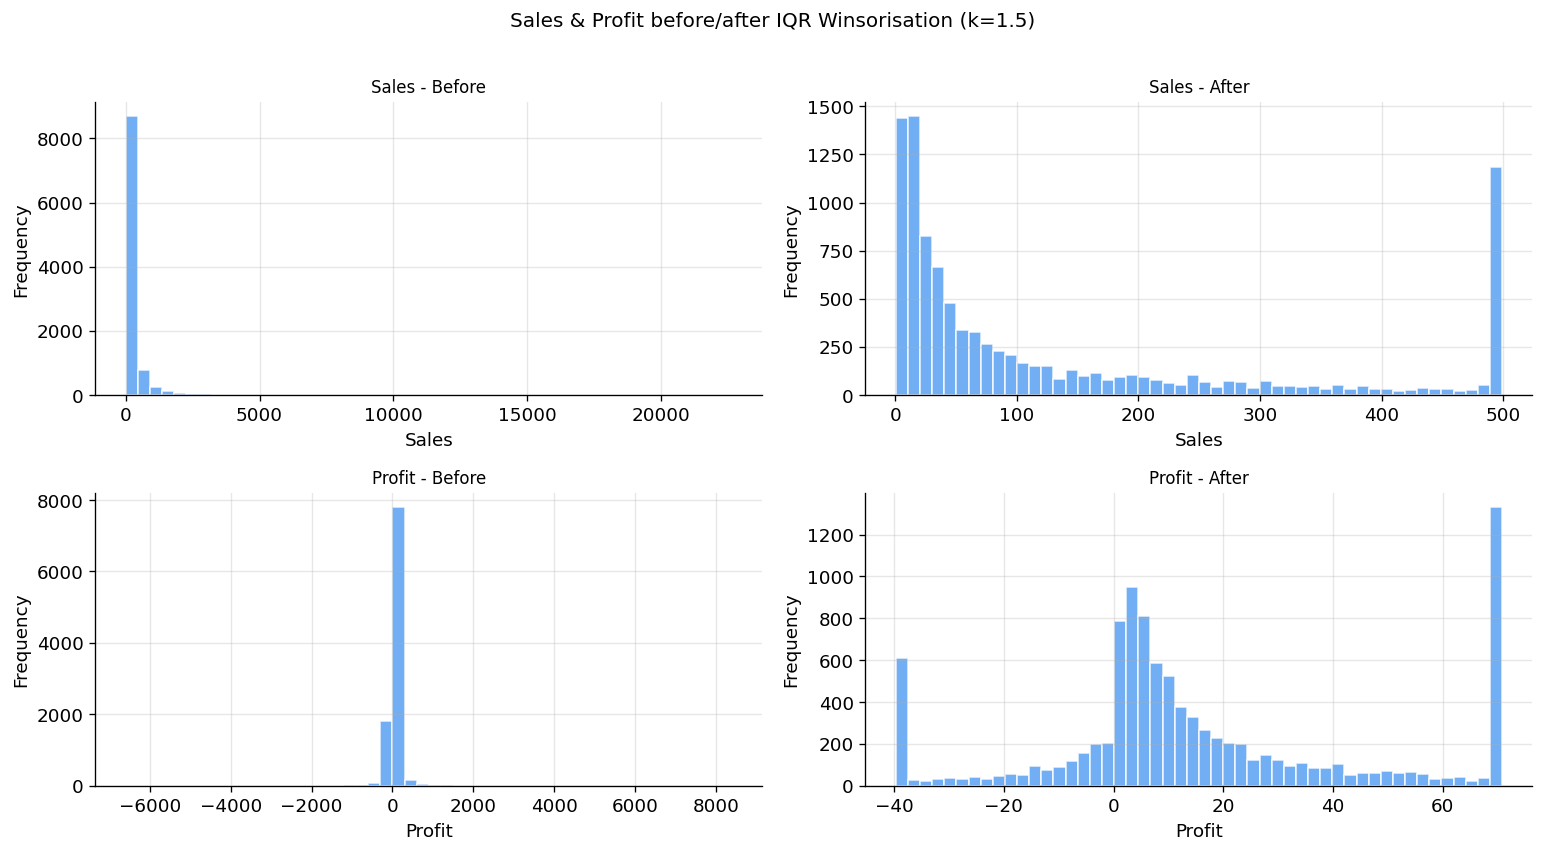

In [ ]:
# 2.2 IQR Winsorisation

def treat_outliers_iqr(df: pd.DataFrame, cols, multiplier=1.5):
    """Cap outliers at [Q1 - k*IQR, Q3 + k*IQR]. Quantity and Discount are
    excluded from this step on purpose: Quantity is bounded by order-line
    rules and Discount sits on a fixed [0, 0.8] interval where high values
    are real promotions."""
    df_out = df.copy()
    records = []
    for col in cols:
        q1, q3 = df_out[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - multiplier * iqr, q3 + multiplier * iqr
        n_out = ((df_out[col] < lower) | (df_out[col] > upper)).sum()
        df_out[col] = df_out[col].clip(lower=lower, upper=upper)
        records.append({
            "column": col,
            "lower_fence": round(lower, 2),
            "upper_fence": round(upper, 2),
            "rows_capped": n_out,
        })
    return df_out, pd.DataFrame(records).set_index("column")


df_clean, fence_report = treat_outliers_iqr(df_num, ["Sales", "Profit"])
print(fence_report.to_string())
print()

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for i, col in enumerate(["Sales", "Profit"]):
    for j, (frame, label) in enumerate([(df_num, "Before"), (df_clean, "After")]):
        frame[col].dropna().plot.hist(bins=50, ax=axes[i][j], color="#4e9af1",
                                      edgecolor="white", alpha=0.8)
        axes[i][j].set_title(f"{col} - {label}", fontsize=10)
        axes[i][j].set_xlabel(col)
        axes[i][j].set_ylabel("Frequency")
plt.suptitle("Sales & Profit before/after IQR Winsorisation (k=1.5)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

The capped values pile up at the fence boundary - a known Winsorisation artefact. I keep `df_num` unwinsorised for analysis that needs the original distribution.

In [ ]:
# 2.3 Sub-group median imputation

def impute_subgroup_median(df: pd.DataFrame, target_col, group_col):
    """Fill NaN in target_col with the per-group median of group_col. Falls
    back to the global median for rows where group_col itself is missing."""
    df = df.copy()
    group_median = df.groupby(group_col)[target_col].transform("median")
    global_median = df[target_col].median()
    df[target_col] = df[target_col].fillna(group_median).fillna(global_median)
    return df


df_imputed = df_clean.copy()
for col in NUMERIC_COLS:
    n = df_imputed[col].isnull().sum()
    if n > 0:
        df_imputed = impute_subgroup_median(df_imputed, col, "Category")
        print(f"Imputed {n} missing values in '{col}' using Category-level median.")

print()
print("Remaining nulls:")
print(df_imputed[NUMERIC_COLS].isnull().sum())

Imputed 1 missing values in 'Sales' using Category-level median.
Imputed 11 missing values in 'Profit' using Category-level median.
Imputed 5 missing values in 'Quantity' using Category-level median.
Imputed 3 missing values in 'Discount' using Category-level median.

Remaining nulls:
Sales       0
Profit      0
Quantity    0
Discount    0
dtype: int64


In [ ]:
# 2.4 Feature engineering

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add five engineered columns:
        profit_margin - Profit / Sales (NaN when Sales is 0)
        days_to_ship - (Ship Date - Order Date) in days
        is_high_discount - 1 if Discount >= 0.3, else 0; preserves NaN
        is_temporal_violation - True if days_to_ship < 0
        revenue_tier - quartile bin label for Sales"""
    df = df.copy()

    df["profit_margin"] = np.where(
        df["Sales"].fillna(0) != 0,
        df["Profit"] / df["Sales"],
        np.nan,)

    df["days_to_ship"] = (df["Ship Date"] - df["Order Date"]).dt.days

    # NaN-preserving: missing Discount stays NaN rather than becoming 0
    df["is_high_discount"] = np.where(
        df["Discount"].isna(),
        np.nan,
        (df["Discount"] >= 0.3).astype(int),)

    df["is_temporal_violation"] = (df["days_to_ship"] < 0).fillna(False).astype(bool)

    df["revenue_tier"] = pd.qcut(
        df["Sales"], q=4,
        labels=["Low", "Mid-Low", "Mid-High", "High"],
        duplicates="drop",)

    print("Engineered feature summary:")
    print(df[["profit_margin", "days_to_ship", "is_high_discount",
              "is_temporal_violation", "revenue_tier"]]
          .describe(include="all").T.to_string())
    return df


df_feat = engineer_features(df_imputed)

Engineered feature summary:
                        count unique    top  freq      mean        std    min    25%       50%   75%       max
profit_margin          9994.0    NaN    NaN   NaN  0.132244    0.40277  -2.75  0.075  0.245905  0.35  0.564065
days_to_ship           9988.0    NaN    NaN   NaN  9.359231  95.406779 -322.0    2.0       4.0  61.0     214.0
is_high_discount       9994.0    NaN    NaN   NaN  0.139284    0.34626    0.0    0.0       0.0   0.0       1.0
is_temporal_violation    9994      2  False  8287       NaN        NaN    NaN    NaN       NaN   NaN       NaN
revenue_tier             9994      4    Low  2501       NaN        NaN    NaN    NaN       NaN   NaN       NaN


In [ ]:
# 2.5 Scaling

SCALE_COLS = ["Sales", "Profit", "Quantity"]

scaler_mm = MinMaxScaler()
scaler_std = StandardScaler()

df_scaled = df_feat.copy()
df_scaled[[f"{c}_minmax" for c in SCALE_COLS]] = scaler_mm.fit_transform(df_feat[SCALE_COLS])
df_scaled[[f"{c}_zscore" for c in SCALE_COLS]] = scaler_std.fit_transform(df_feat[SCALE_COLS])

print(f"Sales_minmax range: [{df_scaled['Sales_minmax'].min():.3f}, "
      f"{df_scaled['Sales_minmax'].max():.3f}]")
print(f"Sales_zscore mean: {df_scaled['Sales_zscore'].mean():.4f}, "
      f"std: {df_scaled['Sales_zscore'].std():.4f}")

# Min-max for [0,1]-bounded models (NN, k-NN); z-score keeps outlier
# distances meaningful for PCA/SVM. Both kept as separate columns.

Sales_minmax range: [0.000, 1.000]
Sales_zscore mean: 0.0000, std: 1.0001


In [ ]:
# 2.6 Groupby aggregation

def segment_summary(df, group_cols, agg_dict, sort_by=None):
    sort_by = sort_by or next(iter(agg_dict))
    return (df.groupby(group_cols, dropna=True)
              .agg(agg_dict)
              .round(2)
              .sort_values(sort_by, ascending=False))


agg_spec = {
    "Sales": "sum",
    "Profit": "sum",
    "profit_margin": "mean",
    "Quantity": "sum",
}

print("--- Performance by Category x Sub-Category ---")
print(segment_summary(df_feat, ["Category", "Sub-Category"], agg_spec).to_string())

print()
print("--- Performance by Region x Segment (top 12) ---")
print(segment_summary(df_feat, ["Region", "Segment"], agg_spec).head(12).to_string())

--- Performance by Category x Sub-Category ---
                                  Sales    Profit  profit_margin  Quantity
Category        Sub-Category                                              
Technology      Phones        222360.84  24881.17           0.11    3288.0
Furniture       Chairs        206182.58  11212.40           0.04    2356.0
Office Supplies Storage       165060.26  12300.60           0.09    3153.0
Technology      Accessories   127450.85  22355.14           0.19    2976.0
Furniture       Tables        117192.07  -1020.37          -0.04    1238.0
Office Supplies Binders       100409.78  11501.26          -0.18    5962.0
Furniture       Furnishings    85028.98  12937.46           0.15    3561.0
Office Supplies Paper          77853.68  28479.36           0.41    5178.0
                Appliances     74669.78  11188.00          -0.03    1729.0
Furniture       Bookcases      71985.62   1475.38          -0.00     868.0
Technology      Machines       44715.78   2772.26    

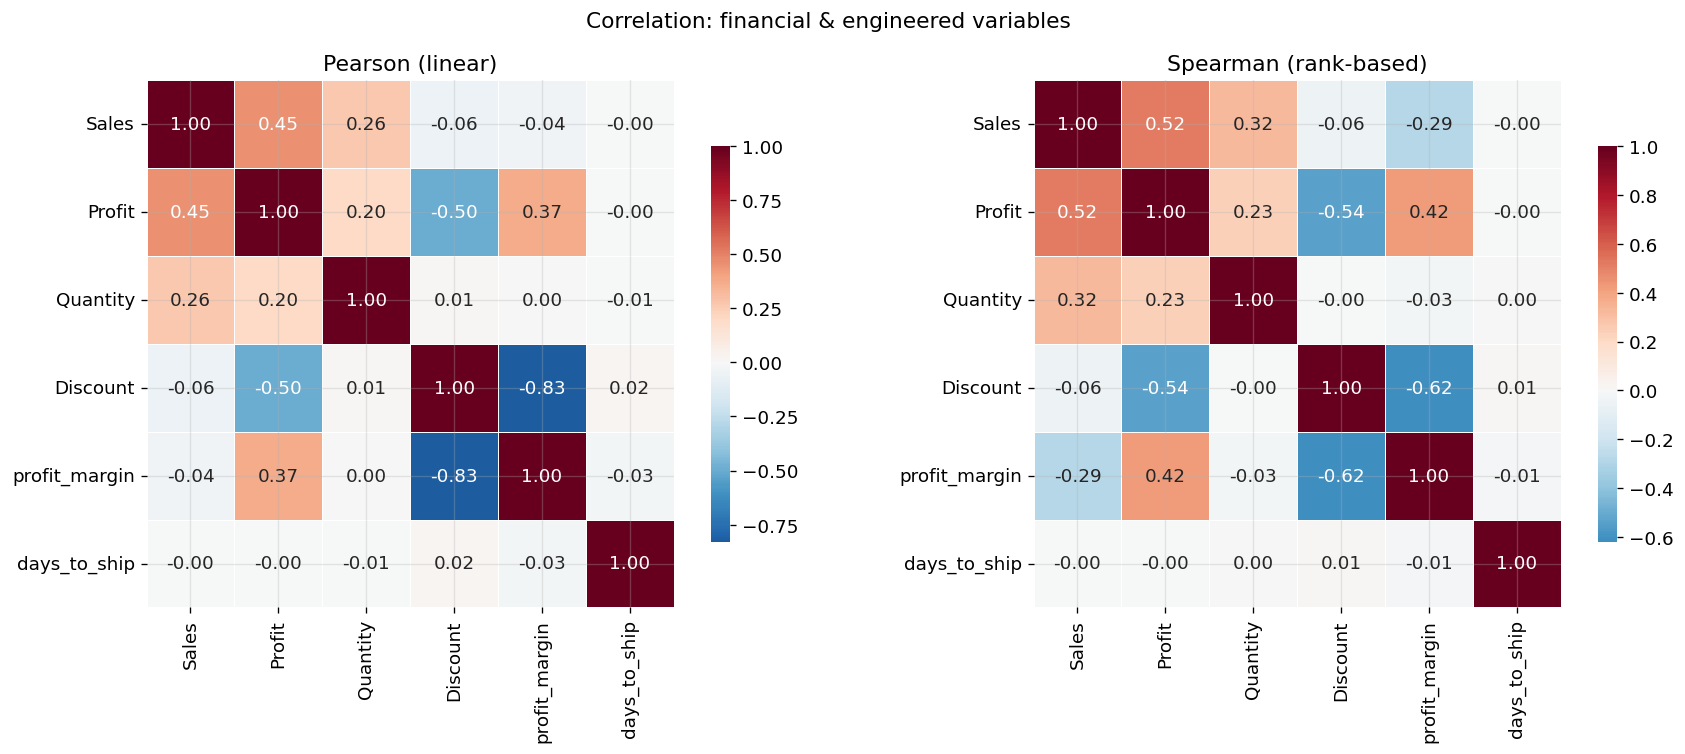

Pearson-Spearman divergence > 0.05 (monotone but nonlinear):
  Sales x profit_margin: delta = 0.253
  Discount x profit_margin: delta = 0.209
  Profit x Sales: delta = 0.064
  Quantity x Sales: delta = 0.060


In [ ]:
# 2.7 Correlation analysis

def correlation_report(df, cols):
    pearson = df[cols].corr(method="pearson")
    spearman = df[cols].corr(method="spearman")

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    kw = dict(annot=True, fmt=".2f", cmap="RdBu_r", center=0,
              square=True, cbar_kws={"shrink": 0.75}, linewidths=0.4)
    sns.heatmap(pearson, ax=axes[0], **kw)
    sns.heatmap(spearman, ax=axes[1], **kw)
    axes[0].set_title("Pearson (linear)")
    axes[1].set_title("Spearman (rank-based)")
    plt.suptitle("Correlation: financial & engineered variables", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

    # Where the two methods diverge by > 0.05, the relationship is monotone
    # but nonlinear - Pearson under-reports it.
    diff = (pearson - spearman).abs()
    pairs = [(r, c, diff.loc[r, c])
             for r in diff.index for c in diff.columns
             if r < c and diff.loc[r, c] > 0.05]
    if pairs:
        print("Pearson-Spearman divergence > 0.05 (monotone but nonlinear):")
        for r, c, v in sorted(pairs, key=lambda x: -x[2]):
            print(f"  {r} x {c}: delta = {v:.3f}")
    else:
        print("No significant Pearson-Spearman divergence.")


correlation_report(df_feat,
                   cols=["Sales", "Profit", "Quantity", "Discount",
                         "profit_margin", "days_to_ship"])

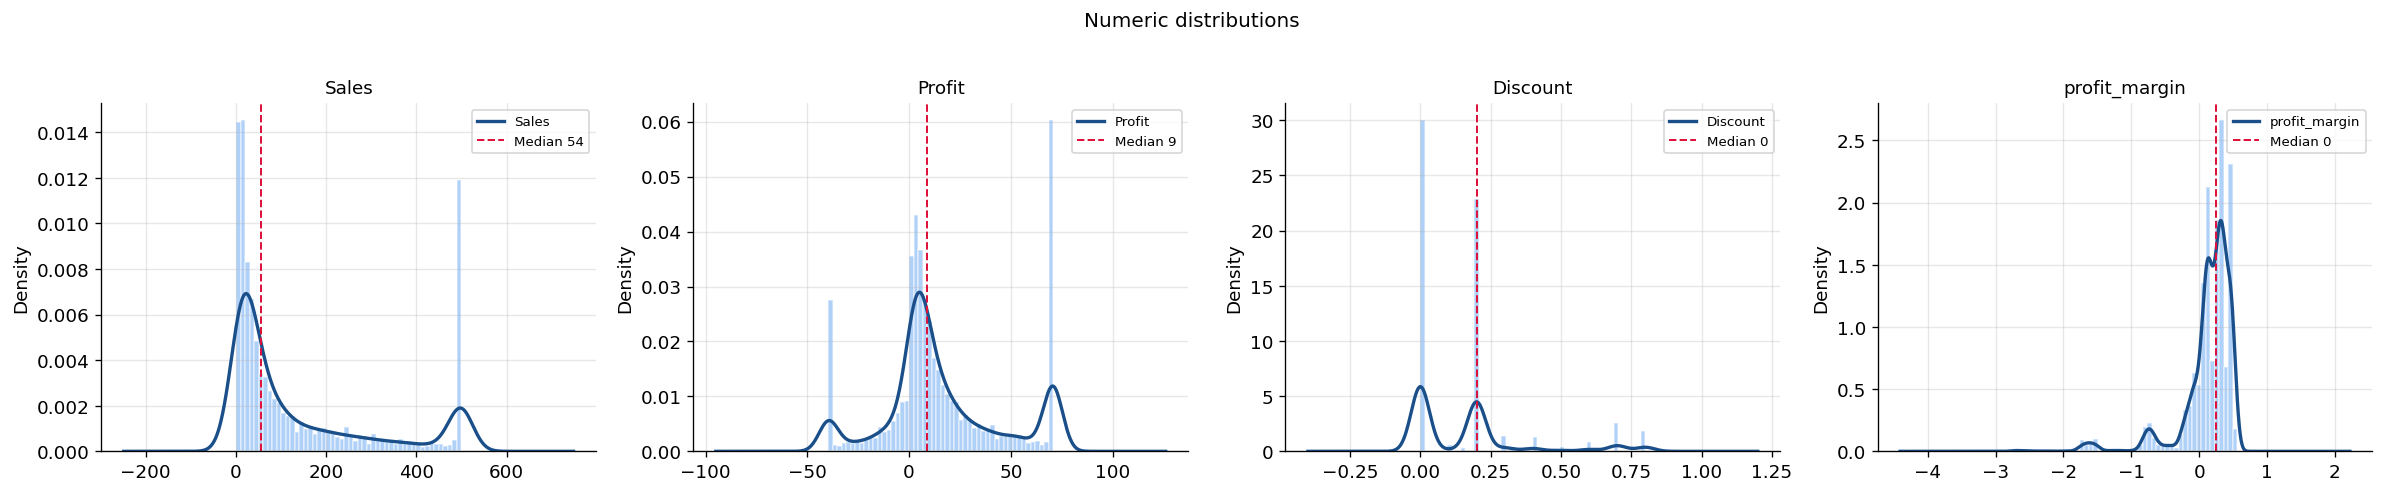

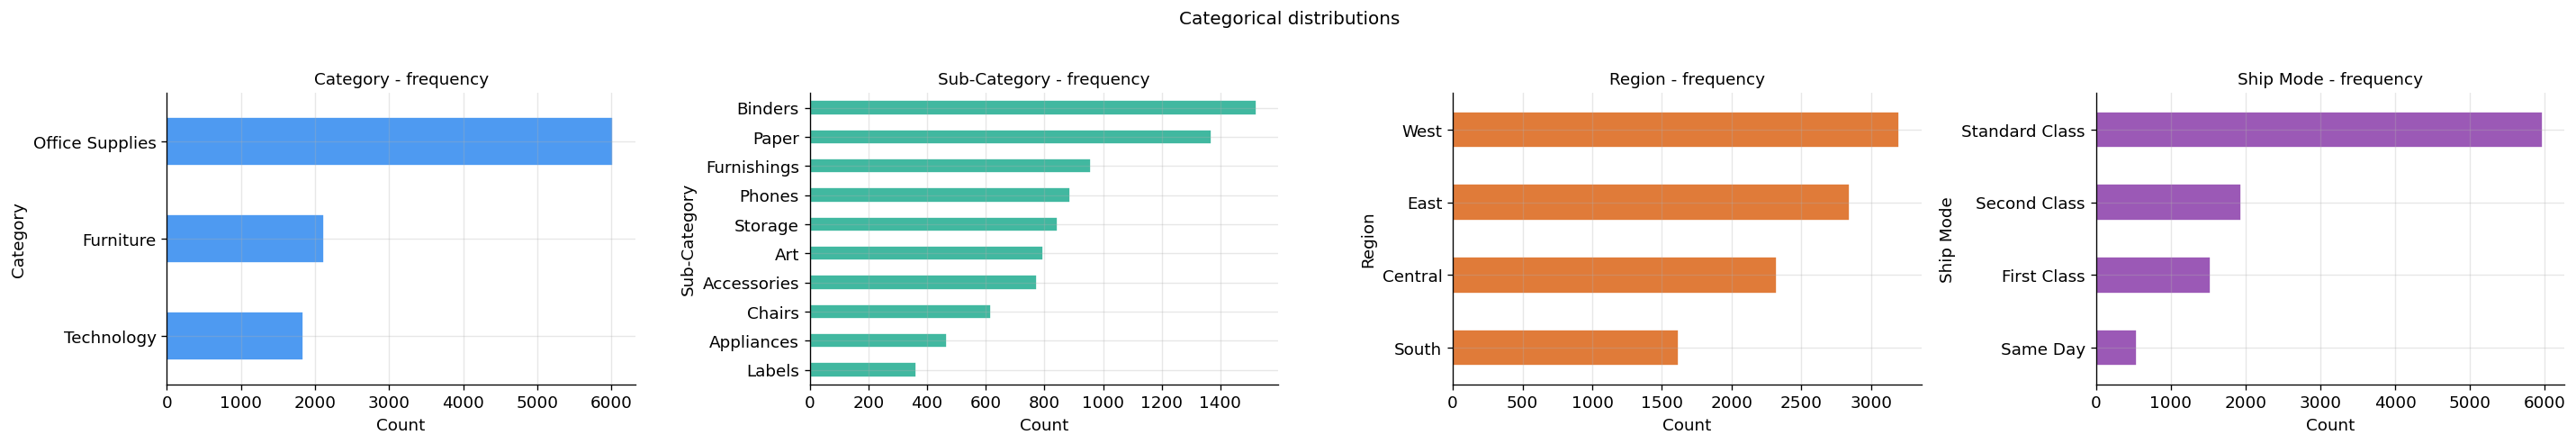

In [ ]:
# 2.8 Univariate distributions

def plot_univariate(df, numeric_cols, cat_cols):
    # Numeric: histogram with KDE overlay - shows multi-modality that
    # boxplots would suppress.
    fig, axes = plt.subplots(1, len(numeric_cols), figsize=(5 * len(numeric_cols), 4))
    for ax, col in zip(axes, numeric_cols):
        data = df[col].dropna()
        ax.hist(data, bins=50, density=True, alpha=0.45, color="#4e9af1", edgecolor="white")
        data.plot.kde(color="#1a4f8a", linewidth=2, ax=ax)
        ax.axvline(data.median(), color="crimson", linestyle="--", linewidth=1.2,
                   label=f"Median {data.median():.0f}")
        ax.set_title(col, fontsize=11)
        ax.set_xlabel("")
        ax.legend(fontsize=8)
    plt.suptitle("Numeric distributions", y=1.02, fontsize=12)
    plt.tight_layout()
    plt.show()

    # Categorical: top-10 frequency bars
    fig, axes = plt.subplots(1, len(cat_cols), figsize=(6 * len(cat_cols), 4))
    if len(cat_cols) == 1:
        axes = [axes]
    colors = ["#4e9af1", "#41b8a0", "#e07b39", "#9b59b6"]
    for ax, col, clr in zip(axes, cat_cols, colors):
        df[col].value_counts().head(10).sort_values().plot.barh(
            ax=ax, color=clr, edgecolor="white")
        ax.set_title(f"{col} - frequency", fontsize=11)
        ax.set_xlabel("Count")
    plt.suptitle("Categorical distributions", y=1.02, fontsize=12)
    plt.tight_layout()
    plt.show()


plot_univariate(df_feat,
                numeric_cols=["Sales", "Profit", "Discount", "profit_margin"],
                cat_cols=["Category", "Sub-Category", "Region", "Ship Mode"])

---
## Task 3: Relationship Analysis & Visual Analytics

**Cat x Cat (Region x Category, normalised heatmap):** chi-square gives significance but no intuition. I row-normalised the heatmap because the operational question is "what mix of products does each region order?" - row-normalisation answers that directly.

**Num x Num (Sales vs Profit, scatter + hexbin):** at n~10K a raw scatter overplots in the low-Sales cluster. I added a hexbin density layer alongside the OLS line (Wilkinson, 2005). Regression is fit on uncapped data so fence values don't bias it.

**Cat x Num (Segment vs Profit, violin + strip):** boxplots hide distribution shape. The violin shows that Consumer and Corporate profit distributions are bimodal; a strip overlay (n=400) anchors it to actual points.

**Discount vs Profit (global vs within-category):** the global Pearson r is -0.495, and stratifying by Category gives similar or stronger negative correlations in every sub-group (Furniture -0.639, Technology -0.501, Office Supplies -0.483). The relationship is consistent across categories, so this is not a reversal paradox; the stratified view confirms and sharpens the global finding. Category is still worth including as a covariate when modelling Profit.


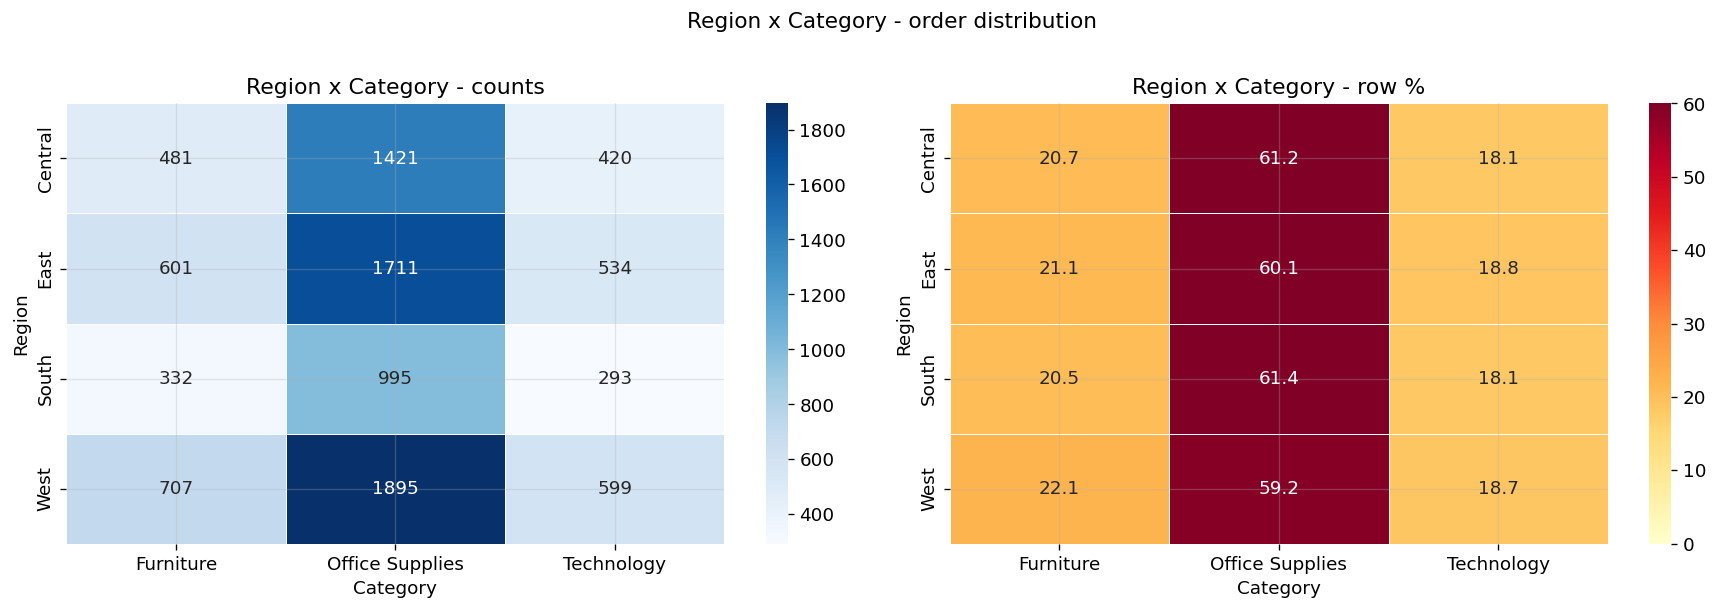

In [ ]:
# 3.1 Cat x Cat: Region x Category

def plot_cat_cat(df, col1, col2, title=""):
    ct = pd.crosstab(df[col1], df[col2], normalize="index").mul(100).round(1)
    ct_raw = pd.crosstab(df[col1], df[col2])

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.heatmap(ct_raw, annot=True, fmt="d", cmap="Blues", linewidths=0.5, ax=axes[0])
    axes[0].set_title(f"{col1} x {col2} - counts")
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlOrRd",
                linewidths=0.5, ax=axes[1], vmin=0, vmax=60)
    axes[1].set_title(f"{col1} x {col2} - row %")
    axes[1].set_xlabel(col2)
    axes[1].set_ylabel(col1)

    plt.suptitle(title or f"{col1} x {col2}", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


plot_cat_cat(df_feat, "Region", "Category",
             title="Region x Category - order distribution")

Office Supplies dominate order counts in every region, but Technology drives most of the revenue (Task 2 groupby). The row-normalised view makes the order-count imbalance visible at a glance.

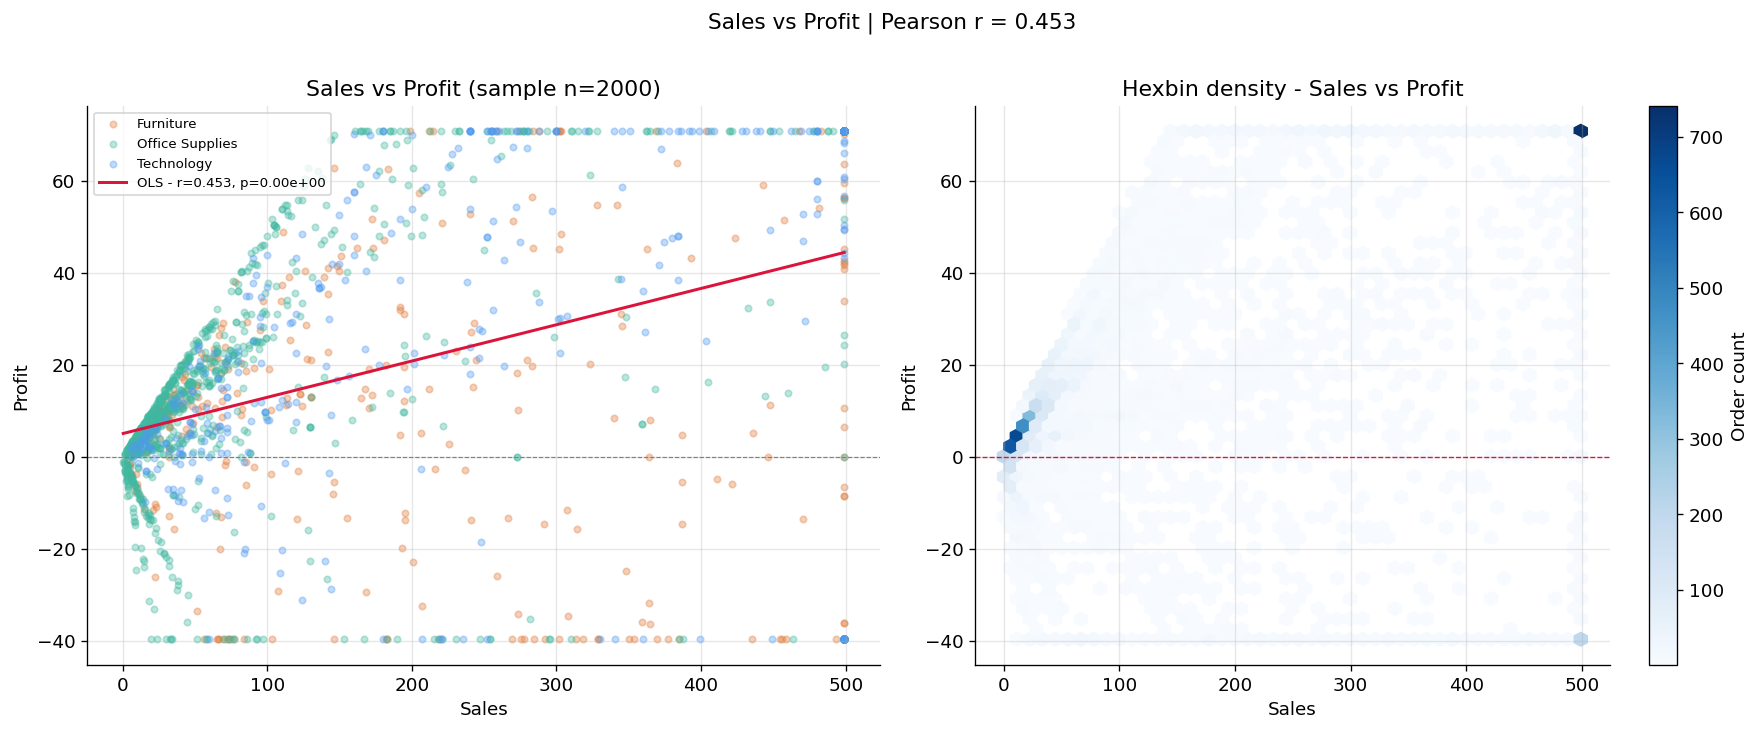

In [ ]:
# 3.2 Num x Num: Sales vs Profit

def plot_num_num(df, x_col, y_col, hue_col=None, sample_n=2000):
    """Scatter + OLS line + hexbin density. Drops NaN pairwise so the
    correlation and OLS use the same row set."""
    paired = df[[x_col, y_col]].dropna()
    r_all, p_all = stats.pearsonr(paired[x_col], paired[y_col])
    m, b = np.polyfit(paired[x_col], paired[y_col], 1)

    sample = paired.sample(min(sample_n, len(paired)), random_state=0)
    if hue_col is not None:
        sample = sample.join(df[[hue_col]], how="left")

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    if hue_col:
        for cat, grp in sample.groupby(hue_col):
            axes[0].scatter(grp[x_col], grp[y_col], alpha=0.35, s=15,
                            label=cat, color=PALETTE.get(cat, "gray"))
    else:
        axes[0].scatter(sample[x_col], sample[y_col], alpha=0.35, s=15, color="#4e9af1")

    xr = np.linspace(paired[x_col].min(), paired[x_col].max(), 200)
    axes[0].plot(xr, m * xr + b, color="crimson", linewidth=1.8,
                 label=f"OLS - r={r_all:.3f}, p={p_all:.2e}")
    axes[0].axhline(0, color="gray", linewidth=0.7, linestyle="--")
    axes[0].set_xlabel(x_col)
    axes[0].set_ylabel(y_col)
    axes[0].set_title(f"{x_col} vs {y_col} (sample n={sample_n})")
    axes[0].legend(fontsize=8)

    hb = axes[1].hexbin(paired[x_col], paired[y_col],
                        gridsize=45, cmap="Blues", mincnt=1)
    plt.colorbar(hb, ax=axes[1], label="Order count")
    axes[1].axhline(0, color="crimson", linewidth=0.8, linestyle="--")
    axes[1].set_xlabel(x_col)
    axes[1].set_ylabel(y_col)
    axes[1].set_title(f"Hexbin density - {x_col} vs {y_col}")

    plt.suptitle(f"{x_col} vs {y_col} | Pearson r = {r_all:.3f}", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()
    return r_all


r_sales_profit = plot_num_num(df_feat, "Sales", "Profit", hue_col="Category")

The Pearson r is positive but moderate. The hexbin shows that most orders cluster at low Sales near break-even Profit; high-Sales orders fan out vertically because discount level swings the Profit outcome.

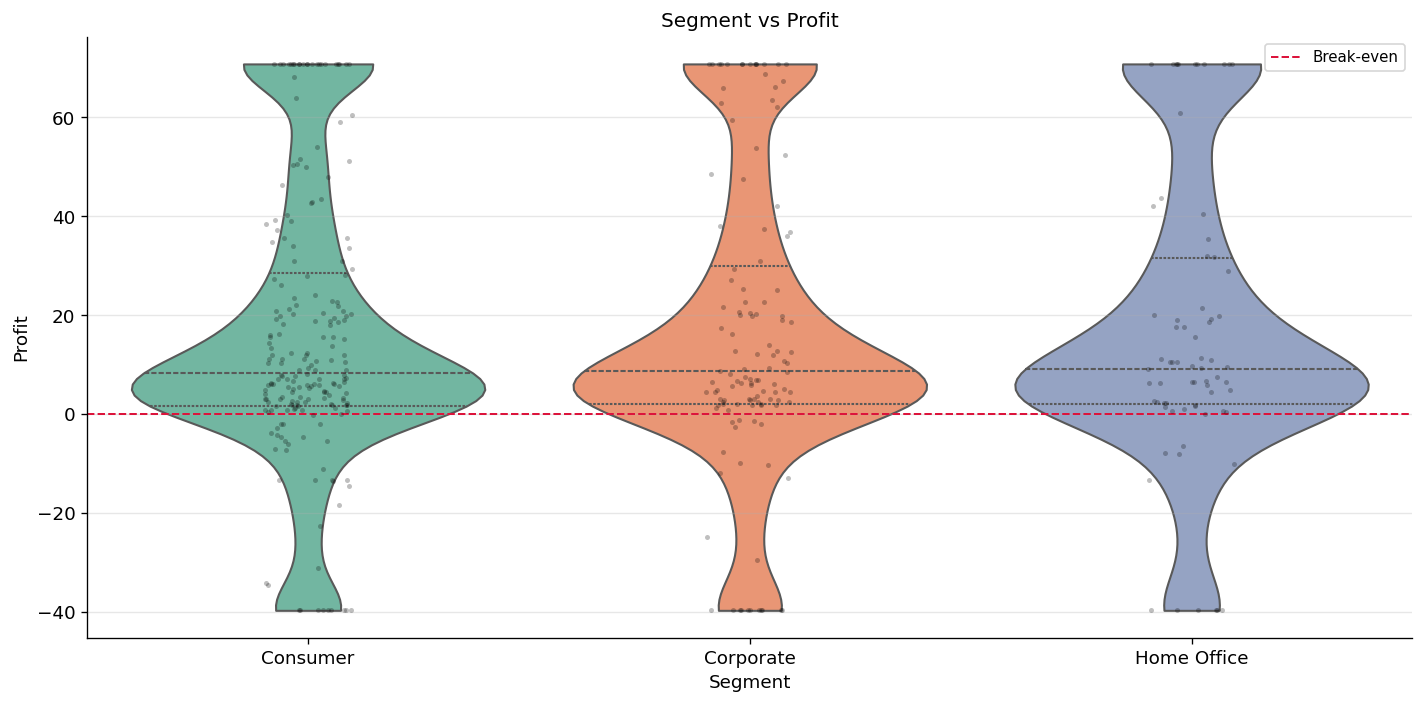

In [ ]:
# 3.3 Cat x Num: Segment vs Profit

def plot_cat_num(df, cat_col, num_col, hue_col=None):
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.violinplot(data=df, x=cat_col, y=num_col, hue=hue_col, palette="Set2",
                   inner="quartile", split=False, cut=0, ax=ax)
    sns.stripplot(data=df.sample(min(400, len(df)), random_state=0),
                  x=cat_col, y=num_col, hue=hue_col,
                  dodge=bool(hue_col), alpha=0.25, size=3, color="black",
                  ax=ax, legend=False)
    if num_col == "Profit":
        ax.axhline(0, color="crimson", linewidth=1.2, linestyle="--",
                   label="Break-even")
        ax.legend(fontsize=9)
    ax.set_title(f"{cat_col} vs {num_col}", fontsize=12)
    ax.set_xlabel(cat_col)
    ax.set_ylabel(num_col)
    plt.tight_layout()
    plt.show()


plot_cat_num(df_feat, "Segment", "Profit")

All three segments contain loss-making orders. Consumer has the widest spread, driven by high-discount Furniture and Technology orders. The violin shape (vs a boxplot) reveals bimodality in Consumer and Corporate that an IQR plot would collapse (Weissgerber et al., 2015).

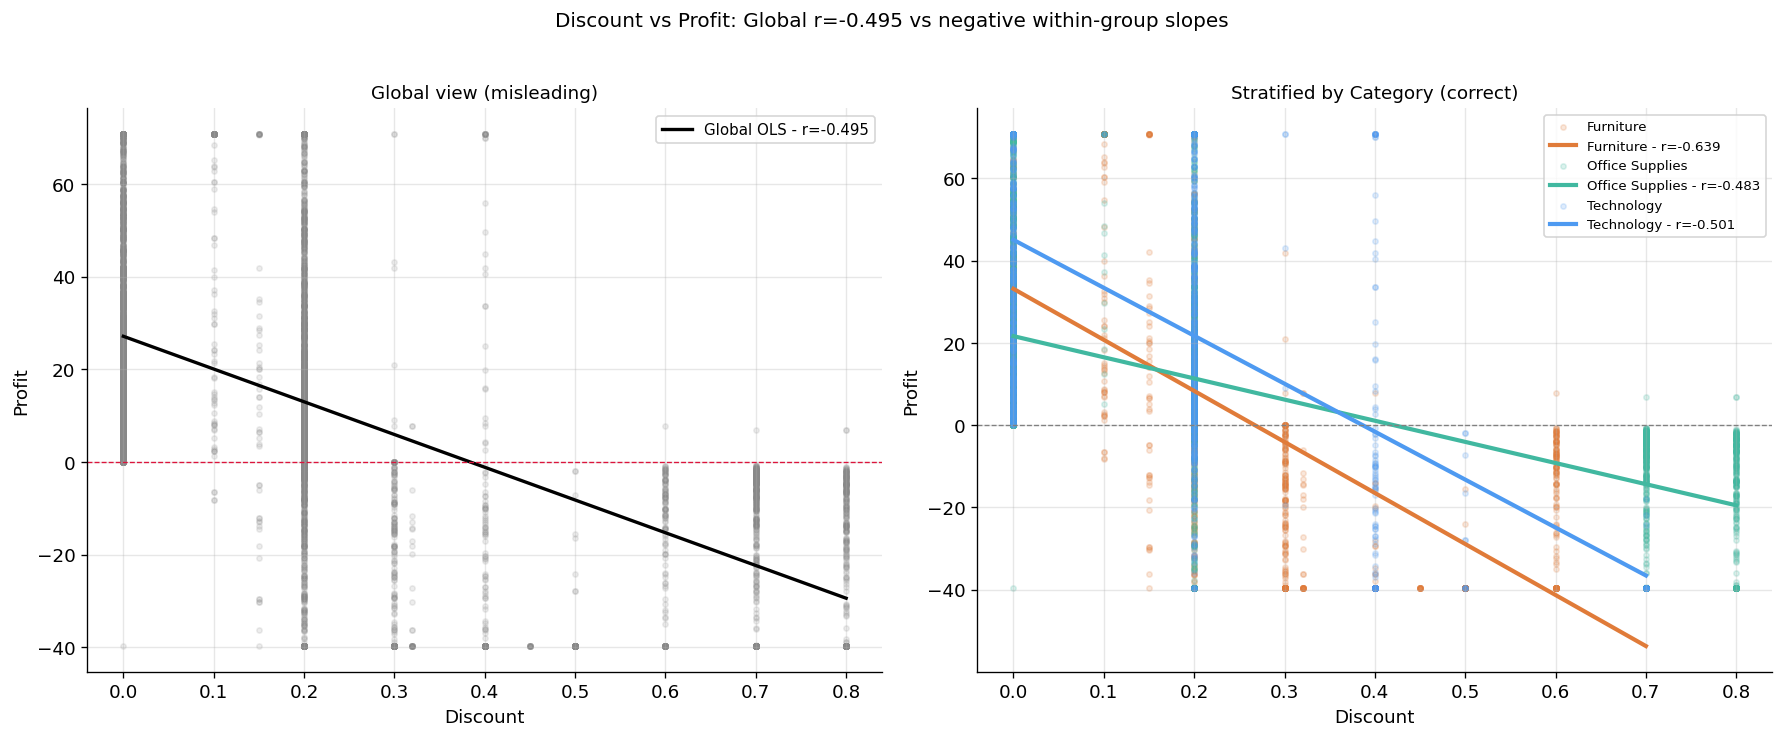

Within-category Pearson r:
  Furniture: r = -0.639
  Office Supplies: r = -0.483
  Technology: r = -0.501
  Global: r = -0.495


In [ ]:
# 3.4 Discount vs Profit: global vs within-category correlation

def plot_discount_profit_by_category(df: pd.DataFrame):
    """Compare the global Discount-Profit correlation with the correlation within each
    Category. Every sub-group has a clearly negative slope, consistent with the global r."""
    df_plot = df.dropna(subset=["Discount", "Profit", "Category"])
    r_global, _ = stats.pearsonr(df_plot["Discount"], df_plot["Profit"])

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Global - misleading
    axes[0].scatter(df_plot["Discount"], df_plot["Profit"],
                    alpha=0.15, s=10, color="#888")
    xg = np.linspace(0, df_plot["Discount"].max(), 100)
    mg, bg = np.polyfit(df_plot["Discount"], df_plot["Profit"], 1)
    axes[0].plot(xg, mg * xg + bg, color="black", linewidth=2,
                 label=f"Global OLS - r={r_global:.3f}")
    axes[0].axhline(0, color="crimson", linewidth=0.8, linestyle="--")
    axes[0].set_title("Global view (misleading)", fontsize=11)
    axes[0].set_xlabel("Discount")
    axes[0].set_ylabel("Profit")
    axes[0].legend(fontsize=9)

    # Stratified - correct
    r_cats = {}
    for cat, grp in df_plot.groupby("Category"):
        col = PALETTE.get(cat, "gray")
        axes[1].scatter(grp["Discount"], grp["Profit"], alpha=0.18, s=10,
                        color=col, label=cat)
        mc, bc = np.polyfit(grp["Discount"], grp["Profit"], 1)
        xc = np.linspace(grp["Discount"].min(), grp["Discount"].max(), 100)
        rc, _ = stats.pearsonr(grp["Discount"], grp["Profit"])
        r_cats[cat] = rc
        axes[1].plot(xc, mc * xc + bc, color=col, linewidth=2.5,
                     label=f"{cat} - r={rc:.3f}")
    axes[1].axhline(0, color="gray", linewidth=0.8, linestyle="--")
    axes[1].set_title("Stratified by Category (correct)", fontsize=11)
    axes[1].set_xlabel("Discount")
    axes[1].set_ylabel("Profit")
    axes[1].legend(fontsize=8)

    plt.suptitle(f"Discount vs Profit: Global r={r_global:.3f} vs negative within-group slopes",
                 fontsize=12, y=1.02)
    plt.tight_layout()
    plt.show()

    print("Within-category Pearson r:")
    for cat, r in r_cats.items():
        print(f"  {cat}: r = {r:.3f}")
    print(f"  Global: r = {r_global:.3f}")
    return r_cats, r_global


r_cats, r_global = plot_discount_profit_by_category(df_feat)

Every sub-group shows the expected negative slope (more discount, lower profit), consistent with the global r of -0.495. Furniture is the steepest (r = -0.639). Category does not reverse or hide the relationship here, so the global and stratified views agree.


---
## Task 4: Code Quality, Modularisation & Reflection

### Design principles applied

Each transformation is a named function (load_data, clean_categoricals, parse_dates, coerce_numerics, treat_outliers_iqr, impute_subgroup_median, engineer_features) that takes a DataFrame and returns a new one. This keeps state out of module scope and makes steps independently testable.

Error handling sits at the I/O boundary (FileNotFoundError, encoding fallback) and the parsing boundary (pd.to_numeric with errors='coerce' plus null-count reporting). run_full_pipeline checks required columns up front and raises ValueError if any are missing.

### Analysis limitation

The pipeline imputes missing Sales, Profit, Quantity, and Discount values using Category-level medians. This assumes values are missing at random within Category, which I haven't tested. If missingness correlates with another feature (for example, high-discount orders being more likely to have a Profit recording error) the imputed values will pull regional and segment summaries toward the median in a biased way. A more thorough analysis would compare missingness patterns across other features before choosing the imputation strategy.


In [ ]:
# 4.1 Full pipeline

def run_full_pipeline(filepath: str, verbose: bool = True) -> pd.DataFrame:
    """End-to-end: load, clean categoricals, parse dates, coerce numerics,
    Winsorise, impute, engineer features. Validates required columns up
    front and raises ValueError if any are missing."""
    REQUIRED = {"Order Date", "Ship Date", "Sales", "Profit",
                "Quantity", "Discount", "Category", "Region"}

    if verbose: print("Step 1/7 - load")
    df = load_data(filepath)

    missing = REQUIRED - set(df.columns)
    if missing:
        raise ValueError(f"Required columns missing: {missing}")

    if verbose: print("Step 2/7 - clean categoricals")
    df = clean_categoricals(df)

    if verbose: print("Step 3/7 - parse dates")
    df = parse_dates(df)

    if verbose: print("Step 4/7 - coerce numerics")
    df = coerce_numerics(df)

    if verbose: print("Step 5/7 - Winsorise")
    df, _ = treat_outliers_iqr(df, cols=["Sales", "Profit"])

    if verbose: print("Step 6/7 - impute")
    for col in ["Sales", "Profit", "Quantity", "Discount"]:
        df = impute_subgroup_median(df, col, "Category")

    if verbose: print("Step 7/7 - engineer features")
    df = engineer_features(df)

    if verbose:
        print(f"\nDone. Shape: {df.shape}, total nulls: {df.isnull().sum().sum()}")
    return df


df_final = run_full_pipeline(DATA_PATH, verbose=True)
print()
df_final[["Order ID", "Category", "Region", "Sales", "Profit",
          "profit_margin", "days_to_ship", "is_high_discount",
          "is_temporal_violation", "revenue_tier"]].head(10)

Step 1/7 - load
Step 2/7 - clean categoricals
Step 3/7 - parse dates
[DATE PARSE] 'Order Date': 1 failure(s). Samples: ['$April']
[DATE PARSE] 'Ship Date': all parsed.
Step 4/7 - coerce numerics
Step 5/7 - Winsorise
Step 6/7 - impute
Step 7/7 - engineer features
Engineered feature summary:
                        count unique    top  freq      mean        std    min    25%       50%   75%       max
profit_margin          9994.0    NaN    NaN   NaN  0.132244    0.40277  -2.75  0.075  0.245905  0.35  0.564065
days_to_ship           9988.0    NaN    NaN   NaN  9.359231  95.406779 -322.0    2.0       4.0  61.0     214.0
is_high_discount       9994.0    NaN    NaN   NaN  0.139284    0.34626    0.0    0.0       0.0   0.0       1.0
is_temporal_violation    9994      2  False  8287       NaN        NaN    NaN    NaN       NaN   NaN       NaN
revenue_tier             9994      4    Low  2501       NaN        NaN    NaN    NaN       NaN   NaN       NaN

Done. Shape: (9994, 26), total nulls: 52



,Order ID,Category,Region,Sales,Profit,profit_margin,days_to_ship,is_high_discount,is_temporal_violation,revenue_tier
0,CA-2016-108196,Technology,East,498.93,-39.69125,-0.079553,-287.0,1.0,True,High
1,US-2017-168116,Technology,South,498.93,-39.69125,-0.079553,0.0,1.0,False,High
2,CA-2014-169019,Office Supplies,Central,498.93,-39.69125,-0.079553,4.0,1.0,False,High
3,CA-2017-134845,Technology,West,498.93,-39.69125,-0.079553,7.0,1.0,False,High
4,US-2017-122714,Office Supplies,Central,498.93,-39.69125,-0.079553,154.0,1.0,False,High
5,CA-2015-147830,Technology,East,498.93,-39.69125,-0.079553,3.0,1.0,False,High
6,CA-2017-131254,Office Supplies,Central,498.93,-39.69125,-0.079553,2.0,1.0,False,High
7,CA-2015-116638,Furniture,South,498.93,7.81710,0.015668,NaN,1.0,False,High
8,CA-2016-130946,Office Supplies,Central,498.93,-39.69125,-0.079553,122.0,1.0,False,High
9,CA-2014-145317,Technology,South,498.93,-39.69125,-0.079553,5.0,1.0,False,High


In [ ]:
# 4.2 Final summary

print("--- Final dataset overview ---")
print(f"Shape: {df_final.shape}")
print(f"Date range: {df_final['Order Date'].min().date()} to "
      f"{df_final['Order Date'].max().date()}")
print(f"Categories: {sorted(df_final['Category'].dropna().unique())}")
print(f"Regions: {sorted(df_final['Region'].dropna().unique())}")
print(f"Avg profit margin: {df_final['profit_margin'].mean():.1%}")
print(f"High-discount rows: {int(df_final['is_high_discount'].sum()):,} "
      f"({df_final['is_high_discount'].mean():.1%})")
print(f"Temporal violations: {df_final['is_temporal_violation'].sum():,} rows")

--- Final dataset overview ---
Shape: (9994, 26)
Date range: 2014-01-02 to 2017-12-30
Categories: ['Furniture', 'Office Supplies', 'Technology']
Regions: ['Central', 'East', 'South', 'West']
Avg profit margin: 13.2%
High-discount rows: 1,392 (13.9%)
Temporal violations: 1,707 rows


---
## References

- Little, R.J.A. & Rubin, D.B. (2002). *Statistical Analysis with Missing Data* (2nd ed.). Wiley.
- Tukey, J.W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- Weissgerber, T.L., Milic, N.M., Winham, S.J. & Garovic, V.D. (2015). Beyond Bar and Line Graphs: Time for a New Data Presentation Paradigm. *PLOS Biology*, 13(4), e1002128.
- Wilkinson, L. (2005). *The Grammar of Graphics* (2nd ed.). Springer.
